<a href="https://colab.research.google.com/github/AlemayehuDabi/RealTime-detection/blob/main/01_object_detection_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q ultralytics

In [3]:
import torch
import sys
from ultralytics import YOLO

print("pytorch version:", torch.__version__)
print("python version:", sys.version)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
pytorch version: 2.14.1+cu130
python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
CUDA available: True


## Import the model

In [4]:
# Load pretrained weights
model = YOLO("yolo26n.pt")

In [5]:
results = model.train(
    data="coco128.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    project="object_detection",
    name="first_training"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=first_training, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

In [6]:
# best checkpoints - save the training so far.

model = YOLO(
    "/content/runs/detect/object_detection/first_training/weights/best.pt"
)


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 1 skateboard, 9.8ms
Speed: 2.3ms preprocess, 9.8ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict


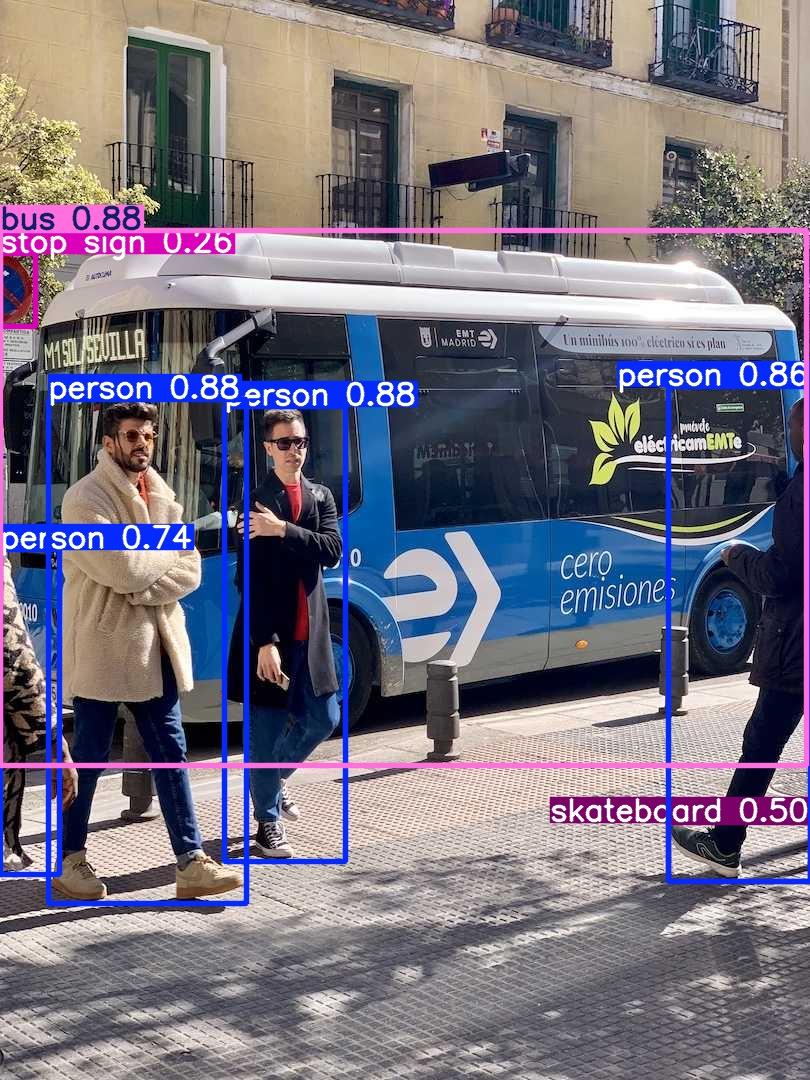

In [7]:
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    save=True
)

from IPython.display import Image, display

display(Image(
    filename=results[0].save_dir and
    "runs/detect/predict/bus.jpg"
))

In [10]:
# we using this model inside our application. download the onnx and use it inside the models/source.
quantaized_model = YOLO(
    "runs/detect/object_detection/first_training/weights/best.pt"
)

model.export(
    format="onnx",
    imgsz=640,
    int8=True,
    simplify=True
)

WARNING ⚠️ 'int8' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
WARNING ⚠️ INT8 export requires a missing 'data' arg for calibration. Using default 'data=coco8.yaml'.
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from 'runs/detect/object_detection/first_training/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.3 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: collecting INT8 calibration images from 'data=coco8.yaml'
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1057.2±448.5 MB/s, size: 54.0 KB)
val: Scanning /content/datasets/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.2Mit/s 0.0s
WARNING ⚠️ ONNX: >300 images recommended for INT8 calibration, found 4 images.
ONNX: quantizing INT

ONNX: export success ✅ 6.4s, saved as 'runs/detect/object_detection/first_training/weights/best_int8.onnx' (2.9 MB)

Export complete (6.8s)
Results saved to /content/runs/detect/object_detection/first_training/weights/best_int8.onnx
Predict:         yolo predict task=detect model=runs/detect/object_detection/first_training/weights/best_int8.onnx imgsz=640 
Validate:        yolo val task=detect model=runs/detect/object_detection/first_training/weights/best_int8.onnx imgsz=640 data=/usr/local/lib/python3.13/dist-packages/ultralytics/cfg/datasets/coco128.yaml 
Visualize:       https://netron.app


'runs/detect/object_detection/first_training/weights/best_int8.onnx'


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 1 skateboard, 9.2ms
Speed: 1.9ms preprocess, 9.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict-3


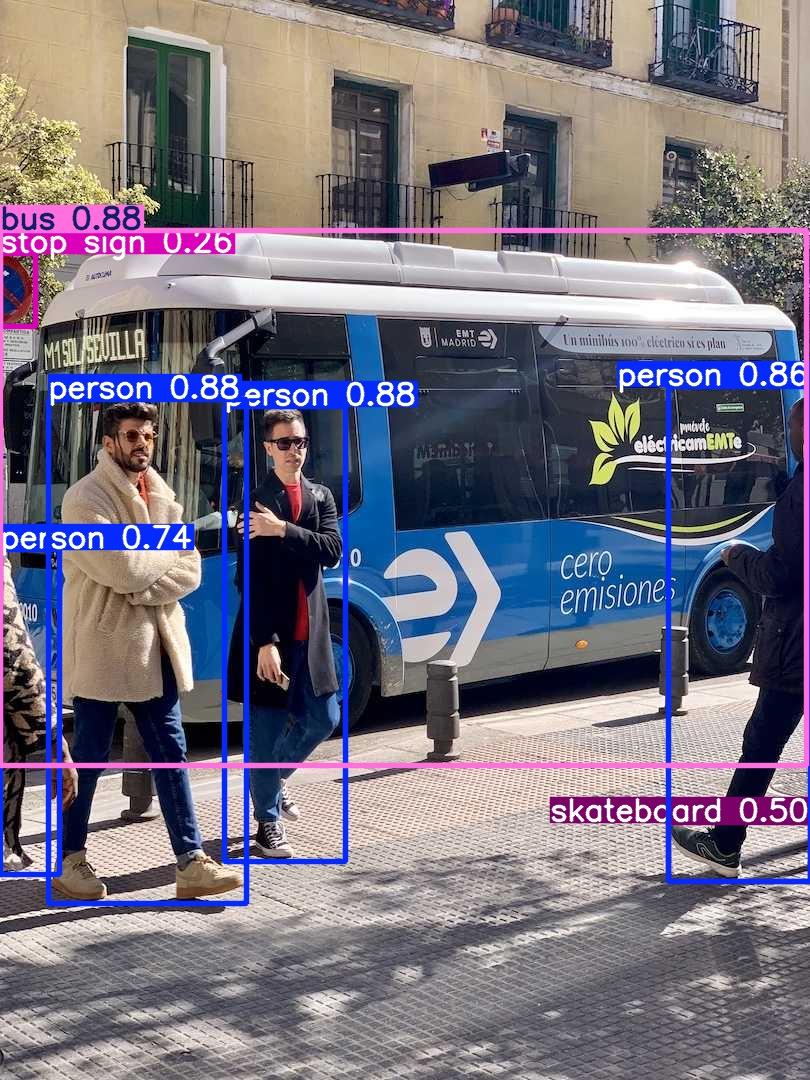

In [11]:
results = quantaized_model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    save=True
)

from IPython.display import Image, display

display(Image(
    filename=results[0].save_dir and
    "runs/detect/predict/bus.jpg"
))